# Demo live: inferensi foto baru dengan 3 model

In [31]:
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image
from ultralytics import YOLO
from torchvision.models.detection import maskrcnn_resnet50_fpn_v2
from torchvision.transforms.functional import to_tensor
from torchvision.utils import draw_segmentation_masks, draw_bounding_boxes

torch.set_num_threads(os.cpu_count())
FOTO = ["foto_baru_20261123_141201.jpg", "foto_interior.jpg"]
NAMES = json.load(open("../results/training/train_config.json"))["NAMES"]  # 72 kelas, urutan sama dengan training

def cari(*paths):
    return next((p for p in paths if os.path.exists(p)), None)

WEIGHTS = {
    "YOLO11s-seg": cari("weights/yolo11s_seg.pt", "../../best.pt"),
    "YOLOv8s-seg": cari("weights/yolov8s_seg.pt"),
    "Mask R-CNN": cari("weights/mask_rcnn_r50.pt", "weights/mask_rcnn_r50.pth"),
}
for k, v in WEIGHTS.items():
    print(f"{k:12s}: {v or 'BELUM ADA, dilewati'}")

YOLO11s-seg : ../../best.pt
YOLOv8s-seg : weights/yolov8s_seg.pt
Mask R-CNN  : weights/mask_rcnn_r50.pt


In [32]:
def load_mrcnn(path):
    m = maskrcnn_resnet50_fpn_v2(weights=None, weights_backbone=None, num_classes=len(NAMES) + 1)
    m.load_state_dict(torch.load(path, map_location="cpu"))
    return m.eval()

MODELS = {}
for name, w in WEIGHTS.items():
    if w:
        MODELS[name] = load_mrcnn(w) if name == "Mask R-CNN" else YOLO(w)
print("Model siap:", list(MODELS))

rng = np.random.default_rng(0)
WARNA = [tuple(int(v) for v in rng.integers(40, 255, 3)) for _ in NAMES]

Model siap: ['YOLO11s-seg', 'YOLOv8s-seg', 'Mask R-CNN']


In [33]:
from PIL import ImageOps

def buka(foto, max_side=1600):
    im = ImageOps.exif_transpose(Image.open(foto)).convert("RGB")
    im.thumbnail((max_side, max_side))
    return im

def predict(name, foto, conf=0.25):
    """Mengembalikan (gambar hasil, daftar (kelas, confidence), waktu ms)."""
    model = MODELS[name]
    pil = buka(foto)
    t = time.perf_counter()
    if name == "Mask R-CNN":
        img = to_tensor(pil)
        with torch.no_grad():
            out = model([img])[0]
        ms = (time.perf_counter() - t) * 1000
        keep = out["scores"] > conf
        labels, scores = out["labels"][keep].tolist(), out["scores"][keep].tolist()
        vis = (img * 255).byte()
        if labels:
            cols = [WARNA[l - 1] for l in labels]
            vis = draw_segmentation_masks(vis, out["masks"][keep, 0] > 0.5, alpha=0.45, colors=cols)
            vis = draw_bounding_boxes(vis, out["boxes"][keep], labels=[f"{NAMES[l - 1]} {s:.2f}" for l, s in zip(labels, scores)],
                                      colors=cols, width=2)
        return vis.permute(1, 2, 0).numpy(), [(NAMES[l - 1], s) for l, s in zip(labels, scores)], ms
    r = model.predict(pil, conf=conf, imgsz=640, device="cpu", verbose=False)[0]
    ms = (time.perf_counter() - t) * 1000
    det = [(r.names[int(c)], float(s)) for c, s in zip(r.boxes.cls, r.boxes.conf)]
    return r.plot()[:, :, ::-1], det, ms

def bandingkan(conf=0.25):
    """Satu baris per foto, satu kolom per model."""
    hasil = {}
    fig, axes = plt.subplots(len(FOTO), len(MODELS), figsize=(5.5 * len(MODELS), 6.5 * len(FOTO)), squeeze=False)
    for i, foto in enumerate(FOTO):
        for j, name in enumerate(MODELS):
            vis, det, ms = predict(name, foto, conf)
            hasil[(foto, name)] = det
            ax = axes[i, j]
            ax.imshow(vis); ax.axis("off")
            ax.set_title(f"{name}  ·  {len(det)} objek  ·  {ms:.0f} ms", fontsize=11)
            if j == 0:
                ax.text(-0.03, 0.5, foto, transform=ax.transAxes, rotation=90, ha="right", va="center", fontsize=10)
    plt.tight_layout(); plt.show()
    return hasil

for name in MODELS:  # pemanasan supaya waktu inferensi berikutnya wajar
    predict(name, FOTO[0])

## Perbandingan 3 model (confidence 0,25)

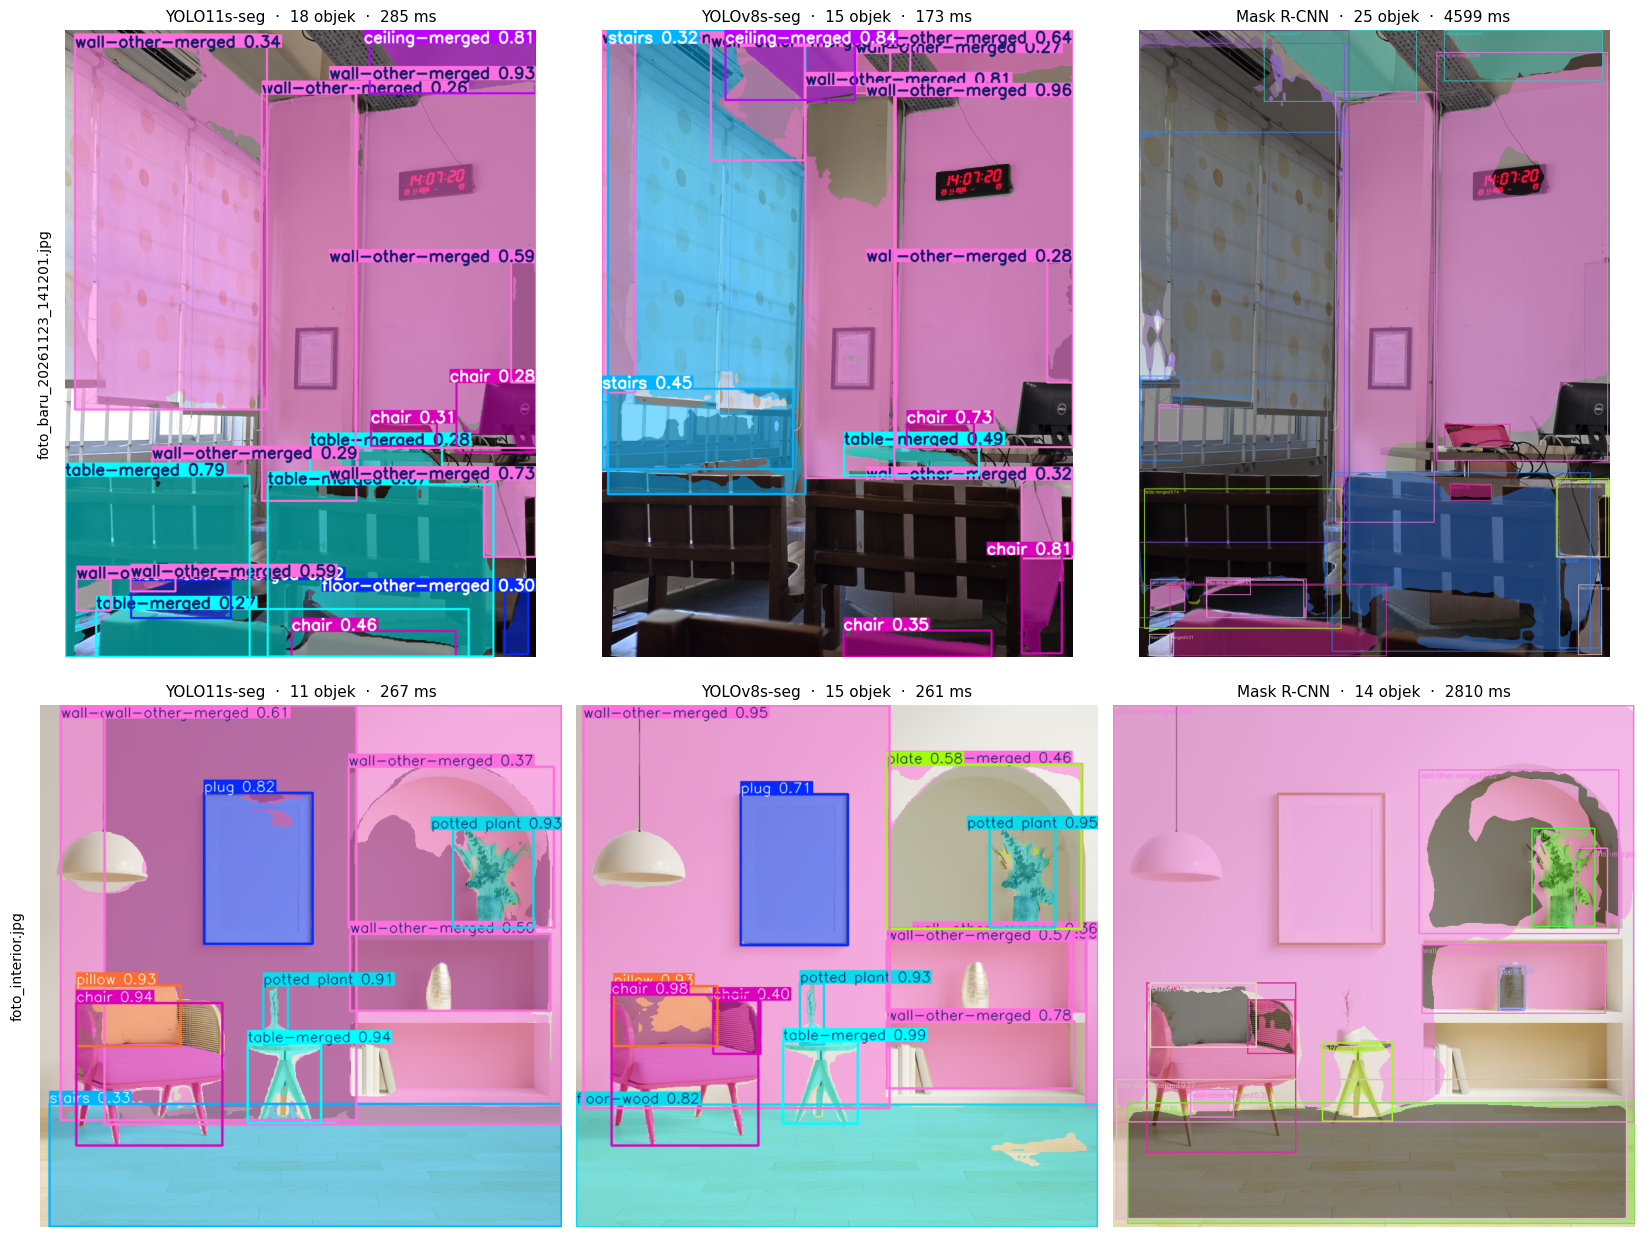

In [34]:
hasil = bandingkan(conf=0.25)

## Jumlah objek per kelas

In [35]:
def tabel(hasil):
    rows = [{"foto": f, "model": m, "kelas": k} for (f, m), det in hasil.items() for k, _ in det]
    if not rows:
        return pd.DataFrame()
    return (pd.DataFrame(rows).groupby(["foto", "kelas", "model"]).size()
            .unstack("model", fill_value=0).sort_index())

tabel(hasil)

model                                             Mask R-CNN  YOLO11s-seg  \
foto                          kelas                                         
foto_baru_20261123_141201.jpg ceiling-merged               2            1   
                              chair                        3            3   
                              floor-other-merged           4            2   
                              stairs                       6            0   
                              table-merged                 2            4   
                              wall-brick                   1            0   
                              wall-other-merged            6            8   
                              window-other                 1            0   
foto_interior.jpg             bottle                       1            0   
                              chair                        2            1   
                              cup                          1            0   
                              floor-other-merged           1            0   
                              floor-wood                   1            0   
                              pillow                       1            1   
                              plate                        0            0   
                              plug                         0            1   
                              potted plant                 1            2   
                              stairs                       0            1   
                              table-merged                 1            1   
                              wall-other-merged            5            4   

model                                             YOLOv8s-seg  
foto                          kelas                            
foto_baru_20261123_141201.jpg ceiling-merged                1  
                              chair                         3  
                              floor-other-merged            0  
                              stairs                        2  
                              table-merged                  1  
                              wall-brick                    0  
                              wall-other-merged             8  
                              window-other                  0  
foto_interior.jpg             bottle                        0  
                              chair                         2  
                              cup                           0  
                              floor-other-merged            0  
                              floor-wood                    1  
                              pillow                        1  
                              plate                         1  
                              plug                          1  
                              potted plant                  2  
                              stairs                        0  
                              table-merged                  1  
                              wall-other-merged             6

## Ubah threshold

Threshold tinggi = lebih sedikit objek, lebih yakin. Ganti angka lalu jalankan ulang cell.

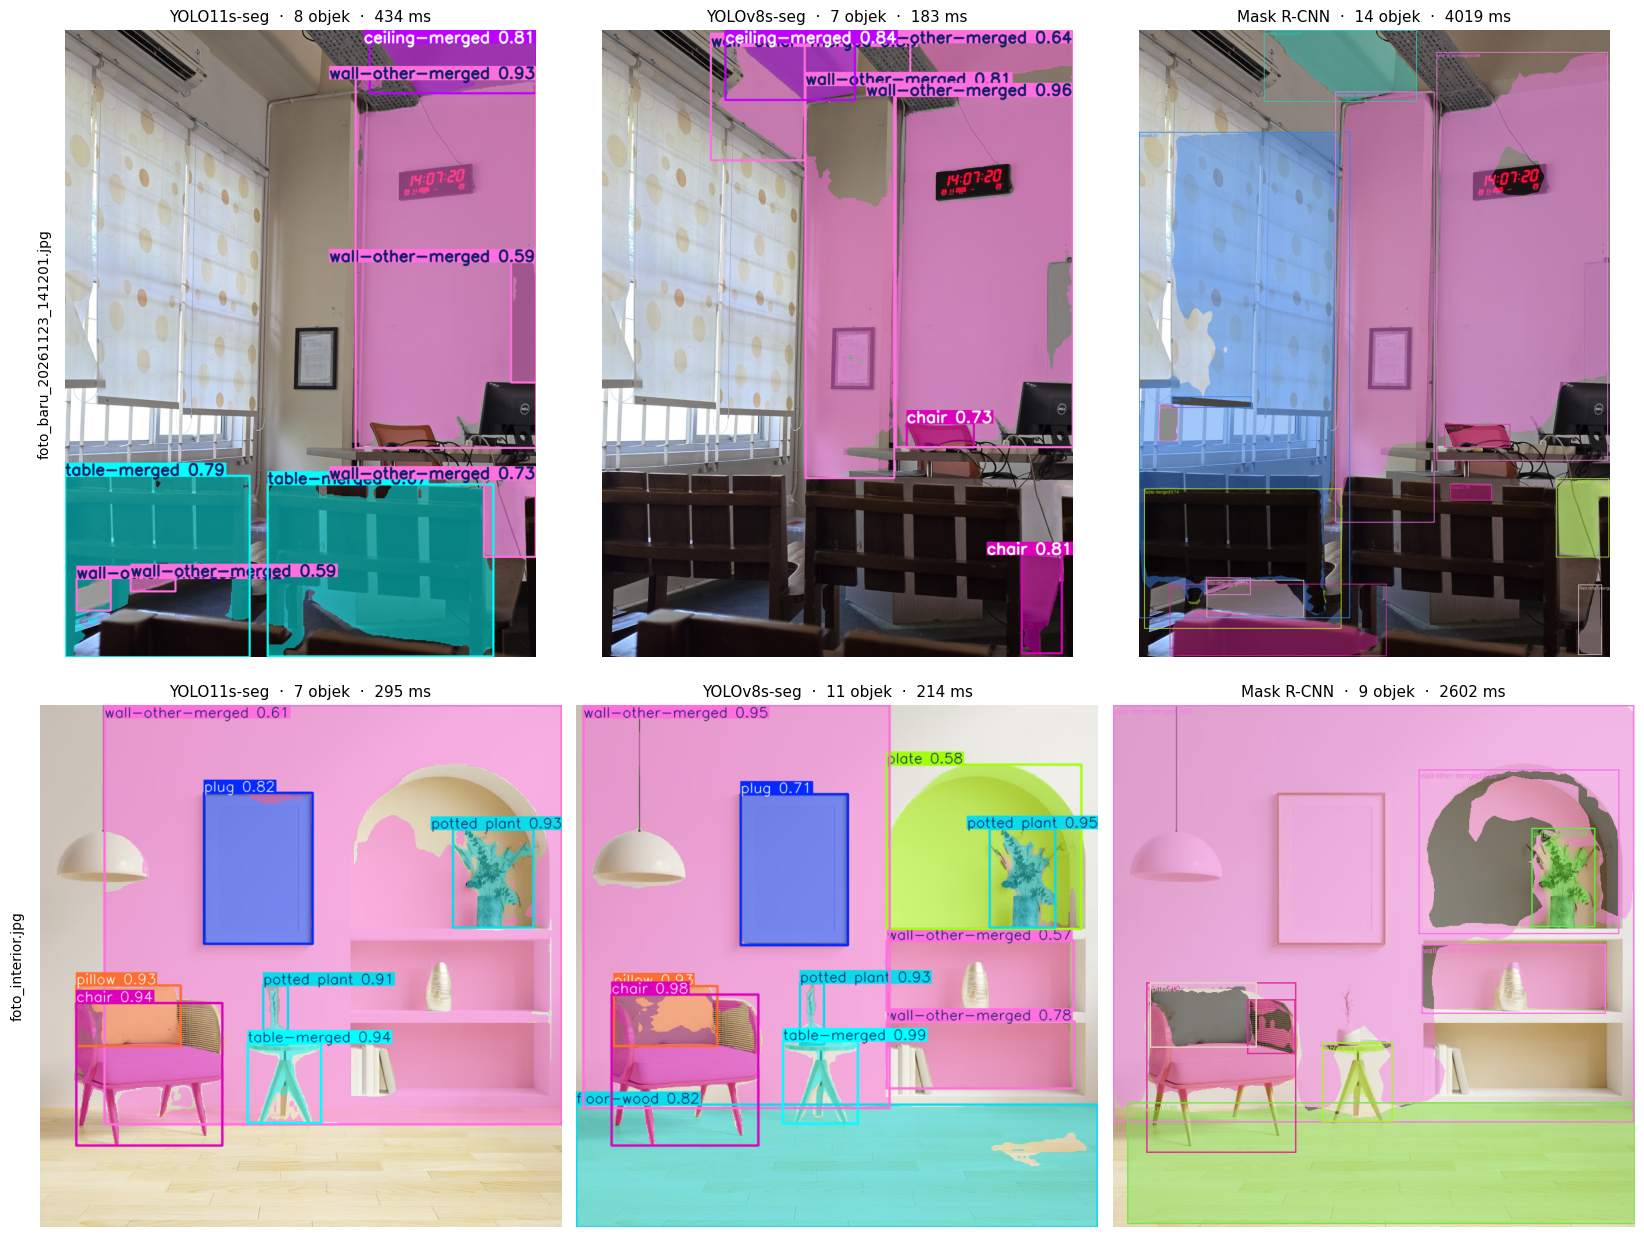

model                                             Mask R-CNN  YOLO11s-seg  \
foto                          kelas                                         
foto_baru_20261123_141201.jpg ceiling-merged               1            1   
                              chair                        3            0   
                              floor-other-merged           2            0   
                              stairs                       2            0   
                              table-merged                 2            2   
                              wall-other-merged            4            5   
foto_interior.jpg             chair                        2            1   
                              floor-wood                   1            0   
                              pillow                       1            1   
                              plate                        0            0   
                              plug                         0            1   
                              potted plant                 1            2   
                              table-merged                 1            1   
                              wall-other-merged            3            1   

model                                             YOLOv8s-seg  
foto                          kelas                            
foto_baru_20261123_141201.jpg ceiling-merged                1  
                              chair                         2  
                              floor-other-merged            0  
                              stairs                        0  
                              table-merged                  0  
                              wall-other-merged             4  
foto_interior.jpg             chair                         1  
                              floor-wood                    1  
                              pillow                        1  
                              plate                         1  
                              plug                          1  
                              potted plant                  2  
                              table-merged                  1  
                              wall-other-merged             3

In [36]:
hasil_05 = bandingkan(conf=0.5)
tabel(hasil_05)

## AP satu kelas (hasil testing v17)

Mask AP50-95 per kelas pada test set asli dan test set HP, dari `results/testing/ap_per_kelas.csv`. Ganti nama kelasnya sesuai permintaan.

In [37]:
AP = pd.read_csv("../results/testing/ap_per_kelas.csv", index_col=0)

def ap_kelas(kelas):
    if kelas not in AP.index:
        print("Kelas tidak ada. Contoh:", ", ".join(AP.index[:15]))
        return
    r = AP.loc[kelas]
    model = ["YOLO11s-seg", "YOLOv8s-seg", "Mask R-CNN R50-FPN v2"]
    return pd.DataFrame({"test asli": [r[f"{m} | asli"] for m in model], "test HP": [r[f"{m} | hp"] for m in model]},
                        index=model).rename_axis(f"{kelas} (objek asli {int(r['objek di test asli'])}, HP {int(r['objek di HP'])})")

ap_kelas("chair")

,test asli,test HP
"chair (objek asli 353, HP 61)",,
YOLO11s-seg,0.225,0.044
YOLOv8s-seg,0.215,0.040
Mask R-CNN R50-FPN v2,0.257,0.074


## Foto baru dari sesi demo

Salin foto ke folder `demo/`, ganti nama file di bawah, lalu jalankan cell ini.

FileNotFoundError: [Errno 2] No such file or directory: 'foto_sesi.jpg'

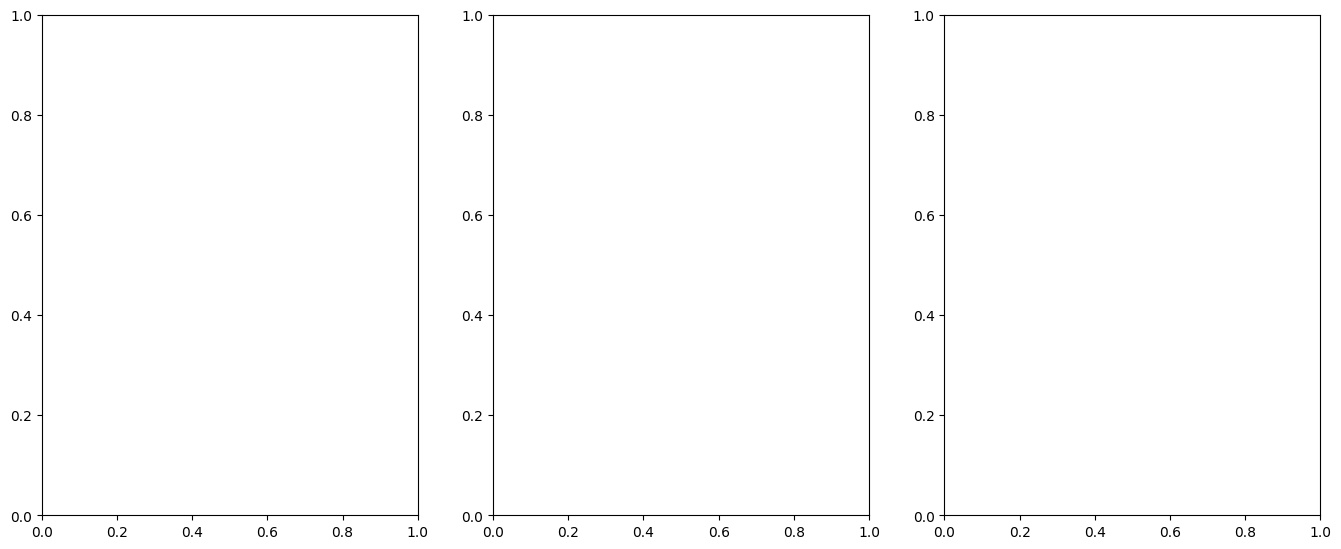

In [38]:
FOTO = ["foto_sesi.jpg"]  # ganti dengan nama foto yang baru diambil
hasil_sesi = bandingkan(conf=0.25)
tabel(hasil_sesi)